<a href="https://colab.research.google.com/github/NeuroNex-ModelX/drainage-failure-sri-lanka/blob/main/01_floods_desinventar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · Flood records (DesInventar) → flood label per DS division × month
**Owner:** Jithmi · **Needs:** notebook 00 · **Makes:** `data/processed/floods_ds_month.csv`

**Before running**, download the Sri Lanka DesInventar data from ONE of these and upload it to
`ModelX/data/raw/desinventar/` (`.zip`, `.xml`, `.csv`, `.xls` or `.xlsx` all work):
1. https://desinventar.cimafoundation.org/DesInventar/download_base.jsp?countrycode=lka (full database, CIMA mirror)
2. https://data.humdata.org/dataset/08c9ca36-8b95-4361-abf1-ce21bfc49184/resource/4cb4bd14-e5ba-4443-af23-948bfb05f479/download/di_report-srilanka.xls (HDX table)
3. https://desinventar-api.undrr.org/DesInventar/download_base.jsp?countrycode=lka (UNDRR, if it is back up)

In [1]:
# --- SETUP ---
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    os.environ['MODELX_BASE'] = '/content/drive/MyDrive/ModelX'
sys.path.append(os.path.join(os.environ.get('MODELX_BASE', '..'), 'src'))
from common import *
import zipfile, subprocess
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

ddir = os.path.join(RAW, 'desinventar')
os.makedirs(ddir, exist_ok=True)
for z in find_files(ddir, [r'\.zip$']):
    with zipfile.ZipFile(z) as zf:
        zf.extractall(ddir)
files = find_files(ddir, [r'\.xml$', r'\.csv$', r'\.xlsx?$'])
print(files)

Mounted at /content/drive
['/content/drive/MyDrive/ModelX/data/raw/desinventar/di_report-srilanka.xls']


### Read the file
The DesInventar XML export holds several tables. The one we need has a column `evento`
(event type) and `fechano` (year). This reader finds it automatically.

In [5]:
def read_desinventar_xml(path):
    """Return {table_name: DataFrame} for every table in a DesInventar XML export."""
    tables, stack = {}, []
    for event, elem in ET.iterparse(path, events=('start', 'end')):
        if event == 'start':
            stack.append(elem.tag)
            continue
        stack.pop()
        kids = list(elem)
        # a 'row' = element whose children are all simple fields
        if len(kids) >= 3 and all(len(k) == 0 for k in kids):
            table = stack[-1] if stack else 'root'
            tables.setdefault(table, []).append({k.tag.lower(): (k.text or '').strip() for k in kids})
            elem.clear()
    return {t: pd.DataFrame(rows) for t, rows in tables.items()}


def fix_header(t):
    """Spreadsheet reports often have title rows above the real header: find the row with 'event'."""
    cols = [str(c).lower() for c in t.columns]
    if any('event' in c for c in cols):
        return t
    for i in range(min(30, len(t))):
        row = [str(v).lower() for v in t.iloc[i].tolist()]
        if any('event' in v or 'evento' in v for v in row):
            t = t.iloc[i + 1:].copy()
            t.columns = row
            return t
    return t


def read_excel_any(path):
    ".xls/.xlsx exports may really be xlsx, old xls, or an HTML table saved as .xls."
    # 1. Try standard pandas excel reading
    for engine in ('openpyxl', 'xlrd'):
        try:
            return pd.read_excel(path, engine=engine)
        except Exception:
            pass

    # 2. Try reading as HTML
    for flavor in [None, 'bs4', 'html5lib']:
        try:
            return pd.read_html(path, flavor=flavor)[0]
        except Exception:
            pass

    # 3. Try reading as text (CSV / Tab-Separated) in case it's a disguised text export
    try:
        return pd.read_csv(path, sep=None, engine='python')
    except Exception:
        pass

    # 4. Manual BeautifulSoup parsing
    try:
        from bs4 import BeautifulSoup
        with open(path, 'r', encoding='utf-8', errors='ignore') as f:
            content = f.read()
        soup = BeautifulSoup(content, 'html.parser')
        table = soup.find('table')
        if table:
            rows = []
            for tr in table.find_all('tr'):
                rows.append([td.get_text(strip=True) for td in tr.find_all(['td', 'th'])])
            if rows:
                return pd.DataFrame(rows[1:], columns=rows[0])
    except Exception:
        pass

    raise ValueError(f"Could not parse {path} as Excel, HTML or text CSV.")


def read_any(path):
    low = path.lower()
    if low.endswith('.xml'):
        return read_desinventar_xml(path)
    if low.endswith('.csv'):
        return {'csv': fix_header(pd.read_csv(path, low_memory=False))}
    return {'excel': fix_header(read_excel_any(path))}


def clean_col(c):
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z0-9_ ]', ' ', str(c).strip().lower())).strip()


if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'xlrd', 'lxml', 'beautifulsoup4', 'html5lib'])

tables = {}
for f in files:
    for name, t in read_any(f).items():
        t.columns = [clean_col(c) for c in t.columns]
        t = t.loc[:, ~pd.Index(t.columns).duplicated()]
        tables[name] = t
        print(f'{name:15s} {t.shape}')

excel           (123062, 29)


In [6]:
# Pick the records table: the one with an event column and a year (or date) column
def find_col(df, patterns):
    for p in patterns:
        hits = [c for c in df.columns if re.fullmatch(p, c)]
        if hits:
            return hits[0]
    return None

EVENT_PATS = [r'evento', r'event', r'event type', r'eventtype', r'.*event.*']
YEAR_PATS = [r'fechano', r'year', r'fecha ano']
DATE_PATS = [r'date.*', r'fecha', r'.*date.*']
rec_name = next(n for n, t in tables.items()
                if find_col(t, EVENT_PATS) and (find_col(t, YEAR_PATS) or find_col(t, DATE_PATS)))
rec = tables[rec_name].copy()
print('Records table:', rec_name, rec.shape)
print('Columns:', rec.columns.tolist())
rec.head(3)

Records table: excel (123062, 29)
Columns: ['serial', 'event', 'code region', 'code district', 'code commune', 'location', 'date ymd', 'duration d', 'source', 'deaths', 'injured', 'missing', 'houses destroyed', 'houses damaged', 'victims', 'affected', 'relocated', 'evacuated', 'losses usd', 'losses local', 'education centers', 'hospitals', 'damages in crops ha', 'lost cattle', 'damages in roads mts', 'unnamed 25', 'unnamed 26', 'unnamed 27', 'unnamed 28']


,serial,event,code region,code district,code commune,location,date ymd,duration d,source,deaths,...,losses local,education centers,hospitals,damages in crops ha,lost cattle,damages in roads mts,unnamed 25,unnamed 26,unnamed 27,unnamed 28
0,FL2008,FLOOD,lka001,lka001002,lka001002018,Telangapatha (GN),02/06/2008,0,EOC,0.0,...,0,0,0,0.0,0,0,NaN,NaN,NaN,NaN
1,FL2008,FLOOD,lka001,lka001002,lka001002018,Wattala (GN),02/06/2008,0,EOC,0.0,...,0,0,0,0.0,0,0,NaN,NaN,NaN,NaN
2,FL2008,FLOOD,lka004,lka004001,lka004001003,Karampon West(GN),19/03/2008,0,DS OFFICE,0.0,...,0,0,0,0.0,0,0,NaN,NaN,NaN,NaN


### Which column is the district and which is the DS division?
Sri Lanka has 25 districts and about 330 DS divisions. We pick the name columns whose
number of distinct values is closest to those numbers. **Check the printout makes sense.**

In [7]:
# If records only carry level codes (level0, level1...), attach names from the lev0/lev1 tables
for lvl in range(3):
    code_col, name_col = f'level{lvl}', f'name{lvl}'
    if code_col in rec.columns and name_col not in rec.columns:
        for t in tables.values():
            cods = [c for c in t.columns if re.fullmatch(rf'lev{lvl}_cod', c)]
            nams = [c for c in t.columns if re.fullmatch(rf'lev{lvl}_name(_en)?', c)]
            if cods and nams:
                rec = rec.merge(t[[cods[0], nams[0]]].rename(columns={cods[0]: code_col, nams[0]: name_col}),
                                on=code_col, how='left')
                break

name_cols = [c for c in rec.columns
             if re.search(r'^name\d$|district|div|^ds|secretar|^level\d name', c) and not pd.api.types.is_numeric_dtype(rec[c])]
nuniq = {c: rec[c].nunique() for c in name_cols}
print(nuniq)
DIST_COL = min(nuniq, key=lambda c: abs(nuniq[c] - 25))
DS_COL = min(nuniq, key=lambda c: abs(nuniq[c] - 330))
print('District column ->', DIST_COL, '| DS column ->', DS_COL)

{'code district': 25}
District column -> code district | DS column -> code district


In [8]:
ev_col = find_col(rec, EVENT_PATS)
yr_col, mo_col = find_col(rec, YEAR_PATS), find_col(rec, [r'fechames', r'month'])
print(rec[ev_col].value_counts().head(20))

event
EPIDEMIC           88411
ANIMAL ATTACK      10815
FLOOD               6801
FIRE                3524
STRONG WIND         2807
RAINS               2533
DROUGHT             2242
LANDSLIDE           2100
GALE                1430
LIGHTNING            528
PLAGUE               423
LAND SUBSIDENCE      187
FOREST FIRE          173
CYCLONE              164
CUTTING FAILURE      164
SNAKE BITE           125
TSUNAMI               89
GROUND VIBRATIO       82
COASTLINE             82
EARTH SLIP            80
Name: count, dtype: int64


In [11]:
flood = rec[rec[ev_col].astype(str).str.contains(r'FLOOD|INUND', case=False, na=False)].copy()
if yr_col and mo_col:
    flood['year'] = pd.to_numeric(flood[yr_col], errors='coerce')
    flood['month'] = pd.to_numeric(flood[mo_col], errors='coerce')
else:   # parse DD/MM/YYYY dates
    date_col = find_col(rec, DATE_PATS)
    ym = flood[date_col].astype(str).str.extract(r'(\d{1,2})\D(\d{1,2})\D(\d{4})')
    flood['year'], flood['month'] = pd.to_numeric(ym[2], errors='coerce'), pd.to_numeric(ym[1], errors='coerce')
n_before = len(flood)
flood = flood[flood['year'].between(1970, 2030) & flood['month'].between(1, 12)]
print(f'{len(flood)} flood records with a valid year and month ({n_before - len(flood)} dropped: no month)')

# Loss columns (Spanish names in the XML export; English in some CSV exports)
LOSS = {'deaths': [r'muertos', r'deaths?'], 'affected': [r'afectados', r'affected.*'],
        'houses_destroyed': [r'vivdest', r'houses destroyed'], 'houses_damaged': [r'vivafec', r'houses damaged']}
for new, opts in LOSS.items():
    c = find_col(flood, opts)
    flood[new] = pd.to_numeric(flood[c], errors='coerce') if c else np.nan

6899 flood records with a valid year and month (2 dropped: no month)


### Match DS names to official pcodes
Unmatched names are written to `data/manual/ds_lookup_desinventar.csv`.
Fill the `pcode` column by hand (look the division up in `data/processed/ds_list.csv`) and re-run this cell.

In [18]:
# Re-initialize and clean the flood slice from raw records first to avoid carrying over old matching states
flood = rec[rec[ev_col].astype(str).str.contains(r'FLOOD|INUND', case=False, na=False)].copy()
if yr_col and mo_col:
    flood['year'] = pd.to_numeric(flood[yr_col], errors='coerce')
    flood['month'] = pd.to_numeric(flood[mo_col], errors='coerce')
else:
    date_col = find_col(rec, DATE_PATS)
    ym = flood[date_col].astype(str).str.extract(r'(\d{1,2})\D(\d{1,2})\D(\d{4})')
    flood['year'], flood['month'] = pd.to_numeric(ym[2], errors='coerce'), pd.to_numeric(ym[1], errors='coerce')

flood = flood[flood['year'].between(1970, 2030) & flood['month'].between(1, 12)]

for new, opts in LOSS.items():
    c = find_col(flood, opts)
    flood[new] = pd.to_numeric(flood[c], errors='coerce') if c else np.nan

# Point columns to district and location textual names
DIST_COL = 'code district'
DS_COL = 'location'

flood = match_ds(flood, DIST_COL, DS_COL, 'ds_lookup_desinventar.csv')
flood = flood[flood['pcode'].notna()]

agg = (flood.groupby(['pcode', 'year', 'month'])
       .agg(n_records=('year', 'size'), deaths=('deaths', 'sum'), affected=('affected', 'sum'),
            houses_destroyed=('houses_destroyed', 'sum'), houses_damaged=('houses_damaged', 'sum'))
       .reset_index())
agg['flood'] = 1
agg.to_csv(os.path.join(PROC, 'floods_ds_month.csv'), index=False)

if not agg.empty:
    first_year, last_year = int(agg['year'].min()), int(agg['year'].max())
    save_meta('flood_records', f'DesInventar Sri Lanka, {first_year}-{last_year}')
    save_meta('flood_last_year', last_year)
    print(f'Saved {len(agg)} flooded division-months, {first_year}-{last_year}')
else:
    print('DataFrame is empty. Please check the matching logic or ds_lookup_desinventar.csv mappings.')

3982 names could not be matched automatically.
   -> open data/manual/ds_lookup_desinventar.csv, fill the 'pcode' column (see data/processed/ds_list.csv), re-run.
Matched 4.0% of rows to a DS division.
Saved 266 flooded division-months, 1974-2013


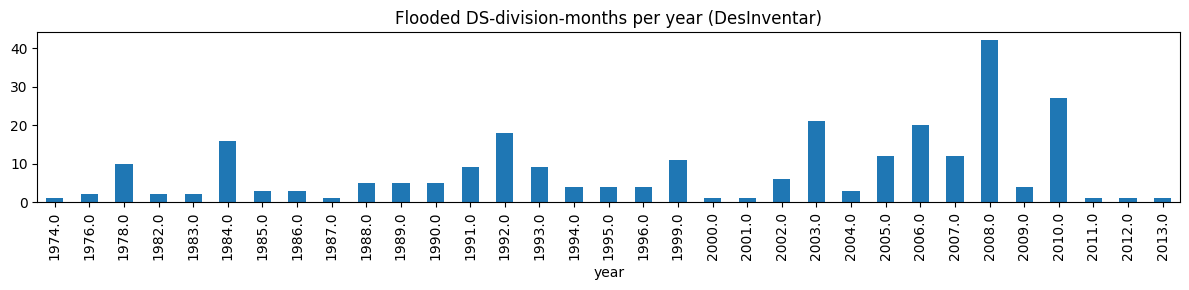

year
2004.0     3
2005.0    12
2006.0    20
2007.0    12
2008.0    42
2009.0     4
2010.0    27
2011.0     1
2012.0     1
2013.0     1
Name: flood, dtype: int64


In [19]:
# IMPORTANT CHECK: what is the last year with records? (decides the train/test split)
per_year = agg.groupby('year')['flood'].sum()
per_year.plot(kind='bar', figsize=(12, 3), title='Flooded DS-division-months per year (DesInventar)')
plt.tight_layout(); plt.show()
print(per_year.tail(10))